#### In this notebook I will look at the time step in the LSM solver, that is, how large gaps can be in the sampeling.

In [1]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

from camera.camera_file import Camera
from camera.spectralCamera import *
from camera.pdeCamera import *
from camera.lsmCamera import LSM
from solvers.help import *

from waves.waveGenCamera import *

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [2]:
# Wave set-up

L   = 2*2*np.pi
N   = 2**7
dt  = 5e-4
c1 = Camera(L,N,dt)
T = 0.05


amps = np.linspace(0.5,2,4)
means = np.zeros_like(amps)
ps    = L*np.ones_like(amps)

In [3]:
kdvp = KdVPacket(ps, amps, means, c1, T)
H = np.array(kdvp.mainloop())
print(H.shape)

(4, 101, 128)


In [4]:
# lets look at the strides:
max = 10
step = np.arange(2,max+1,1)

In [5]:
h_list = [H]
for stride in step:
    h_list.append(H[:,::stride,:])

In [6]:
x_list = []
lsmlist = []
for i,h in enumerate(h_list):
    lsm = LSM(eta_list=h, camera=c1, stride=i+1)
    x_list.append(lsm.lsm())
    lsmlist.append(lsm)

In [7]:
half = N//2

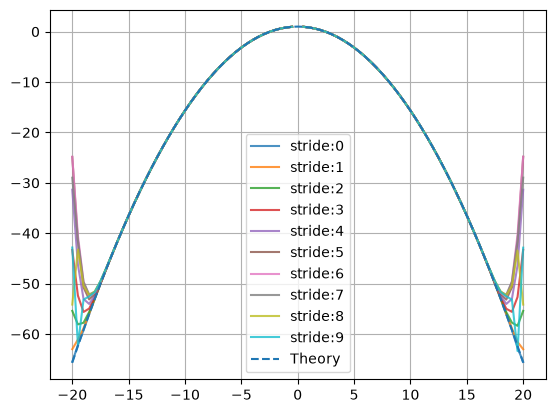

In [13]:
idx = 2*20

order = np.argsort(c1.k)
k = c1.k[order]
# fig, ax = plt.subplots(1,2, figsize = (10,3))

for i,l in enumerate(lsmlist):
    # ell = x_list[i][:,0][order]
    # n   = x_list[i][:,1][order]
    ell = l.ell[order][half-idx:half+idx+1]
    plt.plot(k[half-idx:half+idx+1],ell, label = f"stride:{i}", alpha = 0.8 )

plt.plot(k[half-idx:half+idx+1],kdVDispersion(k[half-idx:half+idx+1]), label = "Theory", linestyle = '--')
plt.legend()
plt.grid()
plt.show()

From the plot it can look like the stride only affects the solution after it has left the true symbol

C:\Users\henri\AppData\Local\Temp\ipykernel_11528\2521491979.py:6: RuntimeWarning: invalid value encountered in divide
  ell_diff = np.abs((lsmlist[i].ell[order] - ref)/ref)


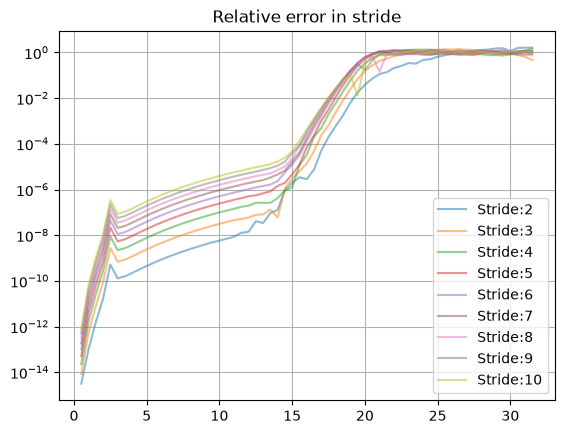

In [10]:
# Using stride 1 as a basis and looking at the error of the other strides

ref = lsmlist[0].ell[order]

for i in range(1,len(lsmlist)):
    ell_diff = np.abs((lsmlist[i].ell[order] - ref)/ref)
    plt.semilogy(k[half:],ell_diff[half:], label = f"Stride:{i+1}", alpha = 0.5)

# plt.semilogy(k[half:], ref[half:])
plt.title("Relative error in stride")
plt.legend()
plt.grid()
plt.show()